# ASTR 596 Computer lab - Characterizing CCDs (50 points)

In this lab you will learn how to:
* read in a CCD image into python
* learn how to display a CCD image
* measure properties of that CCD image
* from a set of CCD Bias frames and Flat field frames, determine the readnoise and gain of the CCD

<i>Note: Enter in all code to the problems in the provided notebook cells. Questions to answer will be <b>bolded</b>.</i>  

<b>You need to execute all code cells regardless of whether they are part of a problem.</b>

All your answers should be entered in this notebook. Each student will need to hand in their own notebook by uploading it to GitHub following the instructions.

In the code places where you will need to put something or write your own code are specified by `#***************`  You will not get points for doing this unless explicitly noted.  Some of these things are just to make sure you are setting up your paths correctly.

**Due on Oct. 21st at Noon** to be handed into the "Characterizing CCDs" assignment in Module 7.

### Import modules

In [4]:
import os
from astropy.io import fits
from astropy.wcs import WCS
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import scoreatpercentile
import glob
%matplotlib inline
from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

### Define a function for displaying images

* We will want to look at images as we examine and analyze the data, so here will will define a function for displaying images. 
* This will handle getting the stretch of the image correct. 
* Feel free to play with the settings and colormap once you get the hang of the process.



In [5]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

### Display raw science image

Text(0.5, 1.0, 'V-band Raw image')

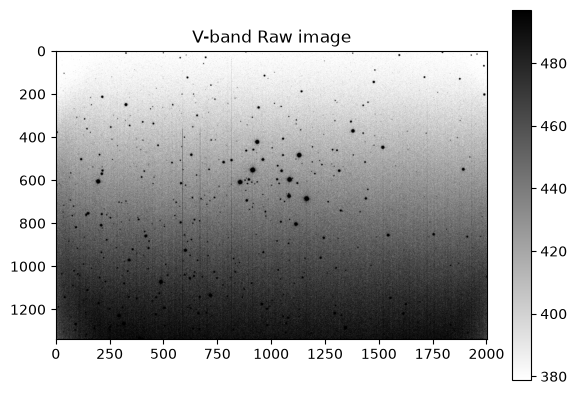

In [6]:
plt.figure()
data_vimraw, header_vimraw = fits.getdata('M29-0005g.fit',header=True)
imdisplay(data_vimraw)
plt.title("V-band Raw image")

### Display processed science image

Text(0.5, 1.0, 'V-band Processed image')

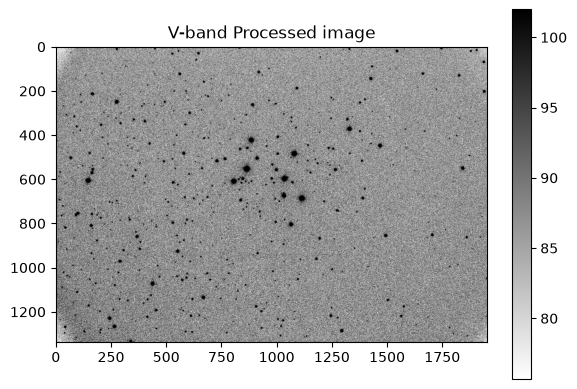

In [7]:
plt.figure()
data_vimproc, header_vimproc = fits.getdata('cazfdp-M29-0005g.fits',header=True)
imdisplay(data_vimproc)
plt.title("V-band Processed image")

## Problem 1 (5 points)

The two images above are the same exact image except that one is raw and one has been fully processed.  In the cell below, describe the origin of the differences between the two images.  I want you to be precise.  NOTE: This CCD has no overscan region so we only have the combined bias frames.  Also pay attention to the values in the colorbar.

The first difference I noticed between the two images is that while the raw image has a gradient in the background, the processed image seems to have a single color in the background around the color bar values of 86-87. In the processed image, you can also see more of the objects that were hidden by the gradient/dark points in the raw image and the ones you could see in the raw image become clearer in the processed one. There also isn't any of the lines that you could see in the raw image in the processed image. 

### Display two flat field images

Text(0.5, 1.0, 'B-band Sky Flat')

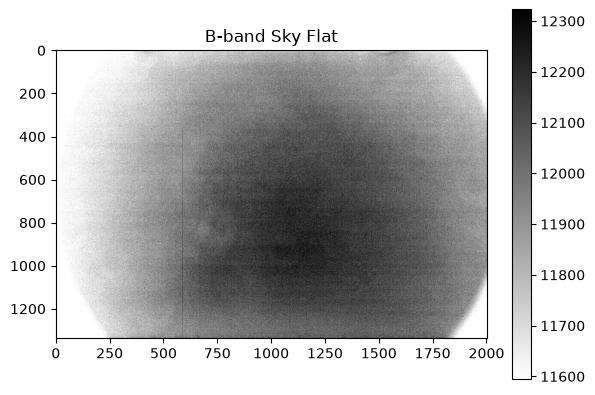

In [8]:
plt.figure()
data_flatb, header_flatb = fits.getdata('skyflat-0001b.fit',header=True)
imdisplay(data_flatb,v2perc=99)
plt.title("B-band Sky Flat")

Text(0.5, 1.0, 'V-band Sky Flat')

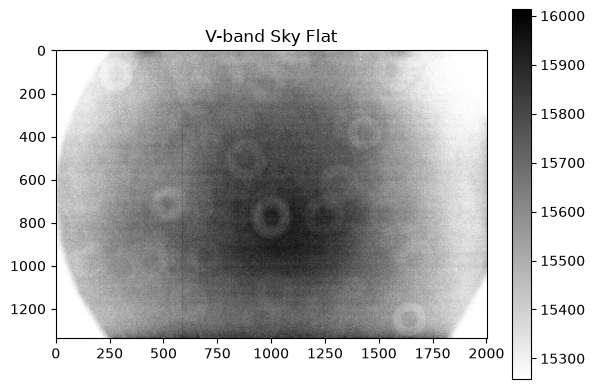

In [9]:
plt.figure()
data_flatv, header_flatv = fits.getdata('skyflat-0001v.fit',header=True)
imdisplay(data_flatv,v2perc=99)
plt.title("V-band Sky Flat")

## Problem 2 (5 points)
The two images above are two different flat field images.  The total number of counts depends on the brightness of the sky in the filter you are using at the time of observation.  Aside from a difference in the total counts, describe what the origins could be of the differences in the flatfields.  Pay attention to differences both at the large scale and the short scale.  

It is not required for the problem, but if you would like to better understand the differences between the two images, you can write a short bit of code that divides the two data arrays and then displays them.

answer goes here: Well I mean right away, the biggest difference between these flatfields I can see is that the v-band one has these little spots on it, with a more opaque ring surrounding each of the spots. On a large scale, the differences could be caused by the region of which you're observing in, maybe the atmosphere or other light bleeding into the observation area. I think on a small scale it could be dust that's on the lens or something of that nature. 

### Display or manipiulate a section of an image

You can feed sections of images to functions and they will either perform the necessary operations, or in the following case, display only those sections.  You may find it useful to consult the first python notebook we did, which had instructions on how to slice arrays.

## Problem 3 (5 points) - properly display a region of the image

You will need to complete the section of code below to display rows 400-900 and columns 750-1250.  You must compare the cutout to the full image above to make sure you are properly addressing rows and columns.

Text(0.5, 1.0, 'cutout of V-band image')

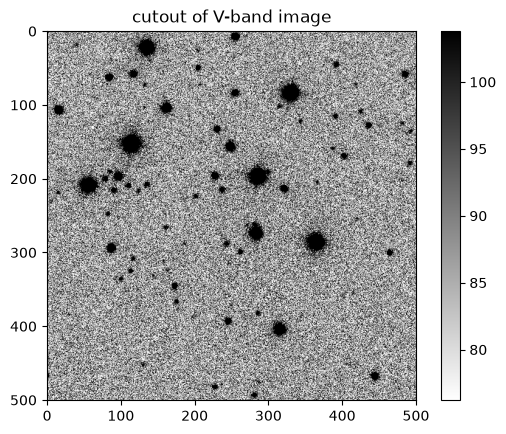

In [10]:
#to display only a section of an image you can perform the following operation
#this displays the section of the image
#***************** fill in the missing array range.
imdisplay(data_vimproc[400:901, 750:1251]) #rows, then columns
plt.title("cutout of V-band image")
#NOTE: that it renumbers the pixels and does *not* refer back to the original image.  
#It also bases the colorbar stretch on the pixels in the subsection that you are displaying

#### Compute statistics on an image
You can pass an image to numpy and compute statistics on it.  In the example below, I show how to compute the standard deviation of all pixel values of a bias image.

I have included two bias images in this directory, numbers 20 and 21


the standard deviation of the Bias frame is 42.08174498305511


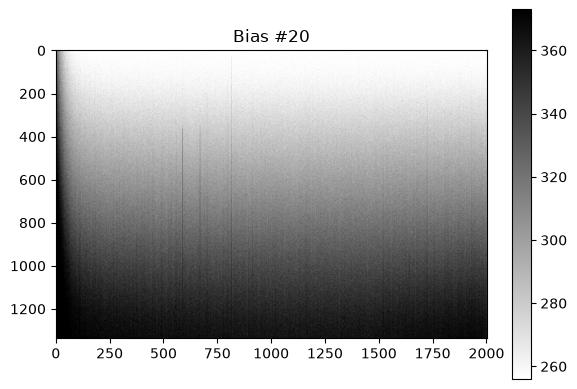

In [11]:
#first read in a bias image
plt.figure()
data_bias1, header_bias1 = fits.getdata('bias-0020.fit',header=True)
imdisplay(data_bias1)
plt.title("Bias #20")

print("the standard deviation of the Bias frame is", np.std(data_bias1))

## Problem 4 (5 points) - Compute the standard deviation of a subsection of the bias image
I would like you to write a peice of well-commented code that
1. displays the bias image extending over rows 600-800 and columns 1000-1200.
2. Measure the standard deviation of the pixels in this section of the bias and print it out.

Then I would like you to explain any differences in the stanard deviation between this subsection and that of the full image.


the standard deviation of the Bias frame is 12.99848062234911


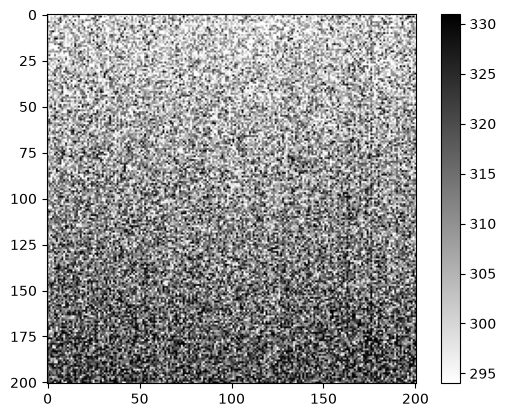

In [12]:
#Put your code here
#***********************
#plt.figure()
#data_bias2, header_bias2 = fits.getdata('bias-0021.fit',header=True) #i just changed the names of the data bias and header bias to
#have a 2 after them instead of a 1. And then I also changed the bias-0020 to bias-0021 to get the bias image 21.
#imdisplay(data_bias2) #displaying the image
#plt.title("Bias #21") #changed the title to the correspodning bias name
#print("The standard deviation of the Bias frame is", np.std(data_bias2)) #calculates the standard dev of the bias 21

#read the problem completely wrong, corrected below

#-------------

sub_data_bias1 = data_bias1[600:801, 1000:1201] #defined the section of the bias image as the subsection of it
imdisplay(sub_data_bias1) #displaying the image of the subsection 

print("the standard deviation of the Bias frame is", np.std(sub_data_bias1)) #replaced the original data_bias1 with the new sub_data_bias1, defining the
#subsection for the bias image and printing the standard deviation for this section

The standard deviation for this subsection is much smaller than the standard deviation that was calculated for the full image. The subsection standard deviation, 12.99, is a bit over 2 times smaller than the stdev of the full image, which had a value of about 42.08. I think this makes sense considering that the frame of the subsection is also much smaller than the frame of the original image.

## Problem 5 (15 points) - compute the readnoise from two bias frames
Using the coding tools we described above and have used in the class, I would like you to 
1. write a well-commented program that measures the READNOISE using two bias frames and prints it out.  The name of the second bias frame is `bias-0021.fit`, which I have written code to read in. You cannot just use the answer from the question above, which was derived from one bias frame.
2. Describe why you can't jsut use one bias frame.
3. Comment on whether the number you derived is in electrons or ADU and justify your answer.

In [13]:
#read in the other bias image
data_bias2,header_bias2 = fits.getdata("bias-0021.fit",header=True)

#convert both arrays to floating point arrays.  This is needed to make sure that
#arithmetic operations will work as the images are otherwise positive definite (UNSIGNED) integers.
data_bias1 = np.array(data_bias1,"f")
data_bias2 = np.array(data_bias2,"f")

#*******************
#Your code here
#need to take the difference of the stdevs and divide it by the sqrt2 i think --> nope. in lecture slides it says the RMS of the pixels in
#the difference of two bias images is sigma sub RN (which is maybe the stdevs subtracted from one another?) * sqrt2
#but i don't think that's what we're trying to find here, so maybe we do divide?
im21_stdev = np.std(data_bias2) #stdev for bias image 21
im20_stdev = np.std(data_bias1) #stdev for bias image 20
#now to find the difference between them:
stdev_diff = im20_stdev - im21_stdev
#i'm going to try dividing it by the sqrt2 first then multiplying so we'll see --> we are using the one from the slides, so multiply!
readnoise = stdev_diff*np.sqrt(2)

#think i did this wrong so go back and fix later
#maybe need to use the full (sigma sub (total))^2 equation

print("Readnoise of Bias Frame in ADU is = ", readnoise) #this readnoise is given in ADU

Readnoise of Bias Frame in ADU is =  0.1415756474203382


put answer to part 2 and 3 here: 

2. The reason why we can't use just one bias frame is because we wouldn't be able to differentiate between the readnoise of the detector itself and the readnoise of the bias frame.

3. Well I would like to say that the number I derived is in ADU because it was pre-written in the code, but we know this answer is in  ADU and not in electrons because to get the answer in electrons, we would need to find the gain, which is in units of electrons/ADU, and use that to cancel out the units of ADU.

## Problem 6 (15 points) - Compute gain of detector using flat field
1. Using your answer to Problem 5 and statistics of the B-band flat field image above, you will need to write a program that computes the gain of the CCD and prints it out.  Specify the units of the gain.  This will work for any flat-field image, but I just used the B-band (`data_flatb`) so that everyone is on the same page.

2. Include a text field with your mathematical derivation in LaTeX, which you can included in the text field.

3. Check your answer against the value in the header.  You can bring this value using `print(header_flatb['EGAIN'])`, where EGAIN is the header keyword for the gain.  Compute how accurate your estimate is.

**HINT:** You will need to think about the measured standard deviation of the pixel values in a section of the flatfield that is relatively uniform.  You can use that, and your knowledge of Poisson statistics and the way the gain affects the counts, to compute the gain.

In [24]:
#*********** 
#your code goes here
#to find the gain, I think I need to use following formula:  counts - bias frame counts/(difference of stdevs)
#i think i need to find the avg counts for both the bias frames and then subtract them from one another for the num
avg_counts_20 = np.mean(data_bias1)
avg_counts_21 = np.mean(data_bias2)
gain = (avg_counts_21-avg_counts_20)/(im21_stdev - im20_stdev)
#or wait unless I need to do this with the OG image and then use the differences of the bias images? but I don't think the v-band cutout is
#considered the original image


print("gain = ", gain)
#and well gain is supposed to be between 1 and 4-5, which my answer is closer to the higher end of gain

#checking answer:
actual_gain = header_flatb['EGAIN']
print("gain from header keyword = ", actual_gain)
pd = ((gain-actual_gain)/((gain+actual_gain)/2)) *100 #stole this formual from google
print("percentage differece = ", pd) #huge difference between gains, so my answer was definitely off

gain =  4.163853
gain from header keyword =  1.6200000047683716
percentage differece =  87.96397
